In [78]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

In [79]:
df=pd.read_csv('Dataset.csv')

In [80]:
df['sales'] = pd.to_numeric(df['sales'].astype(str).str.replace(',', ''), errors='coerce')
df['profit'] = pd.to_numeric(df['profit'], errors='coerce')
df.fillna(0, inplace=True)

In [81]:
customer_df = df.groupby('customer_name').agg({
    'order_id': 'count',
    'sales': 'sum',
    'profit': 'sum',
    'quantity': 'sum'
}).reset_index()

customer_df.columns = ['customer_name', 'frequency', 'monetary_sales', 'total_profit', 'total_quantity']

print("Customer-level aggregated data shape:", customer_df.shape)
customer_df.head()

Customer-level aggregated data shape: (796, 5)


,customer_name,frequency,monetary_sales,total_profit,total_quantity
0,0,79,27308,2319.93856,304
1,Aaron Bergman,89,24646,4683.20800,301
2,Aaron Hawkins,56,20759,2450.92904,231
3,Aaron Smayling,60,14207,369.16180,211
4,Adam Bellavance,68,20189,4979.97690,262


In [82]:
X = customer_df[['frequency', 'monetary_sales', 'total_profit', 'total_quantity']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

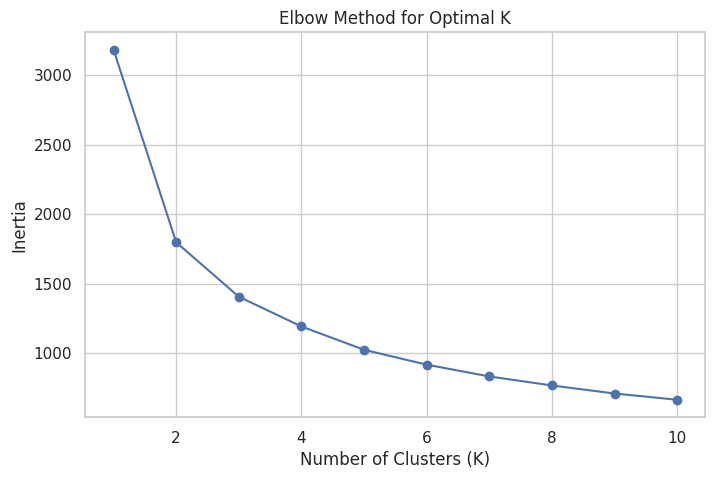

In [83]:
inertia = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o', color='b')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.show()

In [84]:
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
customer_df['cluster'] = kmeans.fit_predict(X_scaled)

print(customer_df['cluster'].value_counts())

cluster
0    318
1    204
3    190
2     84
Name: count, dtype: int64


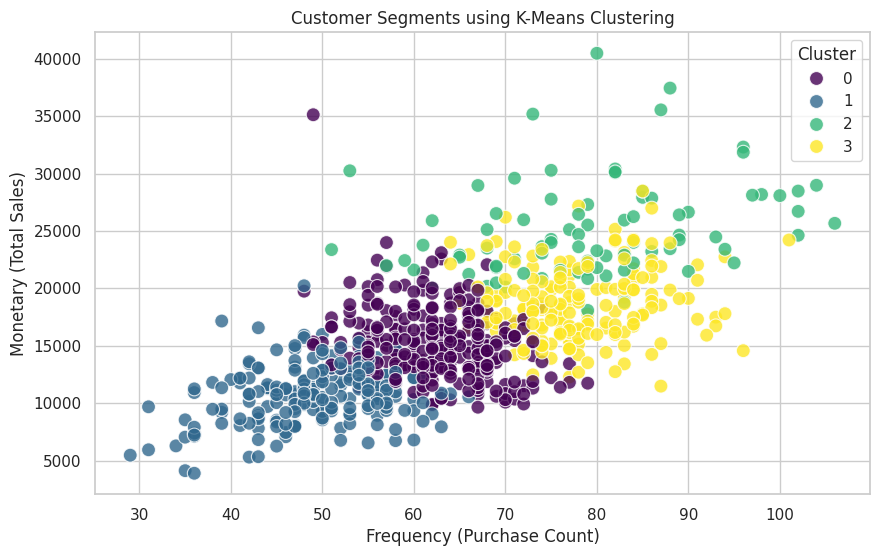

In [85]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=customer_df, x='frequency', y='monetary_sales', hue='cluster', palette='viridis', s=100, alpha=0.8)
plt.title('Customer Segments using K-Means Clustering')
plt.xlabel('Frequency (Purchase Count)')
plt.ylabel('Monetary (Total Sales)')
plt.legend(title='Cluster')
plt.show()

In [86]:
cluster_summary = customer_df.groupby('cluster').agg({
    'frequency': 'mean',
    'monetary_sales': 'mean',
    'total_profit': 'mean',
    'total_quantity': 'mean',
    'customer_name': 'count'
}).rename(columns={'customer_name': 'customer_count'})

print("Segment-wise Insights & Characteristics:\n")
print(cluster_summary)

Segment-wise Insights & Characteristics:

         frequency  monetary_sales  total_profit  total_quantity  \
cluster                                                            
0        62.443396    15084.588050   1727.497582      217.078616   
1        49.098039    10739.833333   1074.451054      164.352941   
2        79.369048    25172.500000   4527.091670      284.130952   
3        77.815789    18679.305263   1688.580113      273.663158   

         customer_count  
cluster                  
0                   318  
1                   204  
2                    84  
3                   190  
